# Flood Mapping with Sentinel-1 Polarimetric SAR - 2. Accuracy Assessment

Loads the change-detection outputs saved by `01_change_detection.ipynb`
(`<name>_<date>.npy` in the results folder), compares them against reference
flood / no-flood masks, and reports ROC / AUC per detector and land-cover class.

> Isundwa et al., *Analytical Optimization of Polarimetric Change Detectors for
> Mapping Open and Grassland Flooding Using Sentinel-1. Case of Rupununi, Guyana.*
> IEEE JSTARS, 2026.

## 1. Imports

In [16]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import auc

try:
    from tqdm import tqdm   # plain tqdm works in console and notebook
except ImportError:                    # no-op fallback if tqdm is missing
    class _NullBar:
        def __init__(self, iterable=None, **k):
            self.iterable = iterable
        def __iter__(self):
            return iter(self.iterable or [])
        def update(self, n=1):
            pass
        def set_postfix_str(self, s):
            pass
        def close(self):
            pass
    def tqdm(iterable=None, **k):
        return _NullBar(iterable, **k)

CSV_COLUMNS = ['Pd', 'Pf', 'threshold', 'accuracy', 'fscore', 'precision']

## 2. Load the detector outputs

Point `RESULTS_DIR` at the **same folder** you saved to in notebook 1, and set
`DATE` to the acquisition tag you used. `load_detectors` reads every
`<name>_<date>.npy` it finds (or pass a list of names for a subset).

In [17]:

RESULTS_DIR = os.path.join('..\\', 'results')

def load_detectors(results_dir, date, ref, names=None):
    """Load detectors saved as <name>_<date>_<ref>.npy."""
    results_dir = str(results_dir)
    out, suffix = {}, f'_{date}_{ref}.npy'
    if names is None:
        for p in sorted(glob.glob(os.path.join(results_dir, f'*{suffix}'))):
            out[os.path.basename(p)[:-len(suffix)]] = np.load(p)
    else:
        for name in names:
            out[name] = np.load(os.path.join(results_dir, f'{name}{suffix}'))
    print(f'Loaded {len(out)} detectors for {date} (ref {ref}) from {os.path.abspath(results_dir)}')
    return out


DATE    = '20170703'
REF_TAG = '03'          # ('03' or '20170329')
det = load_detectors(RESULTS_DIR, DATE, REF_TAG)

for k, v in det.items():
    print(f'  {k:8s} {v.shape}  {v.dtype}')

Loaded 15 detectors for 20170703 (ref 03) from D:\Flood_Mapping_tutorial\results
  Alpha1   (6704, 2734)  float32
  Alpha2   (6704, 2734)  float32
  Dif1     (6704, 2734)  float32
  Dif2     (6704, 2734)  float32
  Lin1     (6704, 2734)  float32
  Lin2     (6704, 2734)  float32
  MonU1    (6704, 2734)  float32
  MonU2    (6704, 2734)  float32
  Rat1     (6704, 2734)  float32
  Rat2     (6704, 2734)  float32
  RatDif   (6704, 2734)  float32
  RatVH    (6704, 2734)  float32
  RatVV    (6704, 2734)  float32
  Trace    (6704, 2734)  float32
  Wishart  (6704, 2734)  float32


## 3. Load the reference masks

Four boolean masks digitised from the optical / drone reference data:

| key | file | meaning |
|---|---|---|
| `grass_flood`   | `Grassland.npy`          | flooded grassland |
| `open_flood`    | `Open_Flood.npy`         | open-water flood |
| `grass_noflood` | `Grassland_No_Flood.npy` | dry grassland |
| `open_noflood`  | `Open_No_Flood.npy`      | dry open areas |

Set `TRANSPOSE = True` if the saved detectors and the masks have opposite
(rows, cols) orientation — the original pipeline stored detectors as
`(samples, lines)` and masks as `(lines, samples)`, so a transpose is usually
needed. The shape check below will tell you if you have it right.

In [18]:
MASK_DIR = os.path.join('..', 'data', 'accuracy_assessment_masks')   

masks = {
    'grass_flood':   np.load(os.path.join(MASK_DIR, 'Grassland_Flood.npy')).astype(bool),
    'open_flood':    np.load(os.path.join(MASK_DIR, 'Open_Flood.npy')).astype(bool),
    'grass_noflood': np.load(os.path.join(MASK_DIR, 'Grassland_No_Flood.npy')).astype(bool),
    'open_noflood':  np.load(os.path.join(MASK_DIR, 'Open_No_Flood.npy')).astype(bool),
}

TRANSPOSE = True   # apply .T to each detector so it matches the masks

# --- shape sanity check ---
a_det = next(iter(det.values()))
det_shape = a_det.T.shape if TRANSPOSE else a_det.shape
mask_shape = masks['grass_flood'].shape
print('detector shape (after TRANSPOSE):', det_shape)
print('mask shape                      :', mask_shape)
assert det_shape == mask_shape, (
    'Shape mismatch - toggle TRANSPOSE or check you loaded the right date/masks')
for k, m in masks.items():
    print(f'  {k:14s} {int(m.sum()):>10,} pixels')

detector shape (after TRANSPOSE): (2734, 6704)
mask shape                      : (2734, 6704)
  grass_flood        16,152 pixels
  open_flood         49,569 pixels
  grass_noflood      28,111 pixels
  open_noflood      226,642 pixels


## 4. Core accuracy function

For one detector / cover / direction, sweep `dim` thresholds between two
percentiles and record Pd, Pf, threshold, accuracy, F-score, precision.
`condition='Greater'` means flood = detector > t; `'Less_than'` the reverse.
(The threshold sweep uses `np.searchsorted` — identical counts to a per-threshold
mask loop, but fast on a full scene.)

In [19]:
def accuracy_assessment(detector, flood_mask, no_flood_mask, dim, condition,
                        save_path=None, pct=(0.1, 93.0)):
    """Sweep dim thresholds; return a DataFrame of ROC metrics (optionally save CSV)."""
    detector = np.asarray(detector)
    flood_mask = np.asarray(flood_mask, dtype=bool)
    no_flood_mask = np.asarray(no_flood_mask, dtype=bool)

    sum_inf = float(flood_mask.sum())
    sum_clean = float(no_flood_mask.sum())

    fv = detector[flood_mask]
    nv = detector[no_flood_mask]
    fv = np.sort(fv[~np.isnan(fv)])
    nv = np.sort(nv[~np.isnan(nv)])

    start = np.nanpercentile(detector, pct[0])
    stop = np.nanpercentile(detector, pct[1])
    t = np.linspace(start, stop, num=dim)

    if condition == 'Greater':
        N_det = fv.size - np.searchsorted(fv, t, side='right')
        N_false = nv.size - np.searchsorted(nv, t, side='right')
    elif condition == 'Less_than':
        N_det = np.searchsorted(fv, t, side='left')
        N_false = np.searchsorted(nv, t, side='left')
    else:
        raise ValueError("condition must be 'Greater' or 'Less_than'")

    with np.errstate(divide='ignore', invalid='ignore'):
        Pd = N_det / sum_inf
        Pf = N_false / sum_clean
        t_neg = 1.0 - Pf
        f_neg = 1.0 - Pd
        prec = Pd / (Pd + Pf)
        rec = Pd / (Pd + f_neg)
        fscore = 2.0 * (prec * rec) / (prec + rec)
        acc = (Pd + t_neg) / 2.0

    df = pd.DataFrame(np.column_stack([Pd, Pf, t, acc, fscore, prec]),
                      columns=CSV_COLUMNS)
    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        df.to_csv(save_path, mode='w', header=False, index=False)
    return df


def auc_from_df(df):
    """Trapezoidal AUC of the ROC implied by a metrics DataFrame."""
    order = np.argsort(df['Pf'].values)
    x = df['Pf'].values[order]
    y = df['Pd'].values[order]
    keep = ~(np.isnan(x) | np.isnan(y))
    x, y = x[keep], y[keep]
    if x.size < 2:
        return np.nan
    return auc(x, y)

## 5. Land-cover class masks

Each cover type combines the four base masks differently. Optionally, detected
open-flood pixels can be added to the grassland no-flood set (as in the paper,
to stop open water leaking into the grassland score).

In [20]:
def cover_masks(masks, cover, open_detected_mask=None):
    gf = masks['grass_flood'];  of = masks['open_flood']
    gnf = masks['grass_noflood']; onf = masks['open_noflood']
    if cover == 'Combined':
        flood = gf | of
        no_flood = gnf | onf
    elif cover == 'Grassland':
        flood = gf
        no_flood = gnf | onf | of
        if open_detected_mask is not None:
            no_flood = no_flood | open_detected_mask.astype(bool)
    elif cover == 'open_flood':
        flood = of
        no_flood = gnf | onf | gf
    else:
        raise ValueError(f'unknown cover type: {cover}')
    return flood, no_flood


# Optional open-flood mask added to the grassland no-flood set.
# RatDif is negative for open flood, so e.g.:
# OPEN_DETECTED = (det['RatDif'].T if TRANSPOSE else det['RatDif']) < -0.01
OPEN_DETECTED = None

## 6. Run the assessment for every detector

Loops all detectors x 3 cover classes x 2 directions and writes one CSV each to
`<OUT_DIR>/<condition>/<cover>_<condition>_<detector>_<date>.csv`.

In [21]:
def assess_all_detectors(detectors, masks, out_path, date, dim=1000,
                         conditions=('Greater', 'Less_than'),
                         covers=('Grassland', 'open_flood', 'Combined'),
                         open_detected_mask=None, transpose=False):
    out_path = str(out_path)
    total = len(detectors) * len(covers) * len(conditions)
    pbar = tqdm(total=total, desc='accuracy')
    for name, d0 in detectors.items():
        d = np.asarray(d0).T if transpose else np.asarray(d0)
        for cover in covers:
            flood, no_flood = cover_masks(masks, cover, open_detected_mask)
            for condition in conditions:
                save_path = os.path.join(
                    out_path, condition, f'{cover}_{condition}_{name}_{date}.csv')
                accuracy_assessment(d, flood, no_flood, dim, condition, save_path)
                pbar.set_postfix_str(f'{name}/{cover}/{condition}')
                pbar.update(1)
    pbar.close()
    print(f'Wrote {len(detectors)} detectors x {len(covers)} covers x '
          f'{len(conditions)} conditions to {os.path.abspath(out_path)}')


OUT_DIR = os.path.join(RESULTS_DIR, f'accuracy_csv_{DATE}')
dim = 1000

assess_all_detectors(det, masks, OUT_DIR, , dim=dim,
                     open_detected_mask=OPEN_DETECTED, transpose=TRANSPOSE)

accuracy: 100%|██████████| 90/90 [00:39<00:00,  2.27it/s, Wishart/Combined/Less_than]  

Wrote 15 detectors x 3 covers x 2 conditions to D:\Flood_Mapping_tutorial\results\accuracy_csv


## 7. AUC summary table

For each detector and cover class, the best threshold direction is chosen
automatically (the one giving the higher AUC), mirroring Table II of the paper.

In [22]:
def auc_summary(detectors, masks, dim=1000,
                conditions=('Greater', 'Less_than'),
                covers=('Grassland', 'open_flood', 'Combined'),
                open_detected_mask=None, transpose=False):
    rows_auc, rows_dir = {}, {}
    for name, d0 in tqdm(detectors.items(), total=len(detectors), desc='AUC'):
        d = np.asarray(d0).T if transpose else np.asarray(d0)
        auc_row, dir_row = {}, {}
        for cover in covers:
            flood, no_flood = cover_masks(masks, cover, open_detected_mask)
            best_auc, best_c = -np.inf, None
            for condition in conditions:
                df = accuracy_assessment(d, flood, no_flood, dim, condition)
                a = auc_from_df(df)
                if np.isfinite(a) and a > best_auc:
                    best_auc, best_c = a, condition
            auc_row[cover] = best_auc if np.isfinite(best_auc) else np.nan
            dir_row[cover] = best_c
        rows_auc[name] = auc_row
        rows_dir[name] = dir_row
    table = pd.DataFrame(rows_auc).T[list(covers)]
    best_dir = pd.DataFrame(rows_dir).T[list(covers)]
    return table, best_dir


table, best_dir = auc_summary(det, masks, dim=dim,
                             open_detected_mask=OPEN_DETECTED, transpose=TRANSPOSE)
table.to_csv(os.path.join(OUT_DIR, f'AUC_summary_{DATE}.csv'))
print('Best threshold direction per detector:')
print(best_dir)
table.round(3)

AUC: 100%|██████████| 15/15 [00:41<00:00,  2.75s/it]

Best threshold direction per detector:
         Grassland open_flood   Combined
Alpha1   Less_than    Greater    Greater
Alpha2     Greater  Less_than  Less_than
Dif1       Greater  Less_than  Less_than
Dif2     Less_than  Less_than  Less_than
Lin1       Greater  Less_than  Less_than
Lin2       Greater  Less_than  Less_than
MonU1      Greater    Greater    Greater
MonU2      Greater    Greater    Greater
Rat1     Less_than  Less_than  Less_than
Rat2       Greater    Greater    Greater
RatDif     Greater  Less_than    Greater
RatVH    Less_than  Less_than  Less_than
RatVV    Less_than  Less_than  Less_than
Trace    Less_than  Less_than  Less_than
Wishart    Greater  Less_than  Less_than


,Grassland,open_flood,Combined
Alpha1,0.543,0.997,0.874
Alpha2,0.564,0.828,0.716
Dif1,0.633,0.951,0.831
Dif2,0.748,0.891,0.887
Lin1,0.745,0.899,0.748
Lin2,0.954,0.950,0.730
MonU1,0.821,0.963,0.991
MonU2,0.708,0.990,0.960
Rat1,0.488,0.828,0.767
Rat2,0.827,0.966,0.996


## 8. ROC overview plot

Best-direction ROC of every detector for one cover class (log10 Pf vs Pd),
like Fig. 8 of the paper.

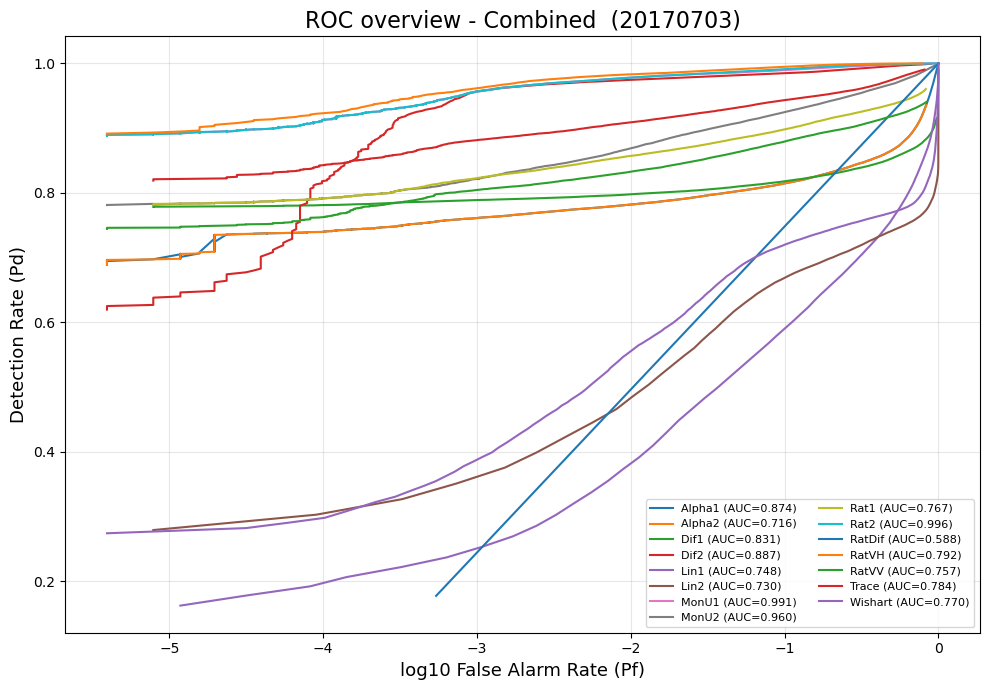

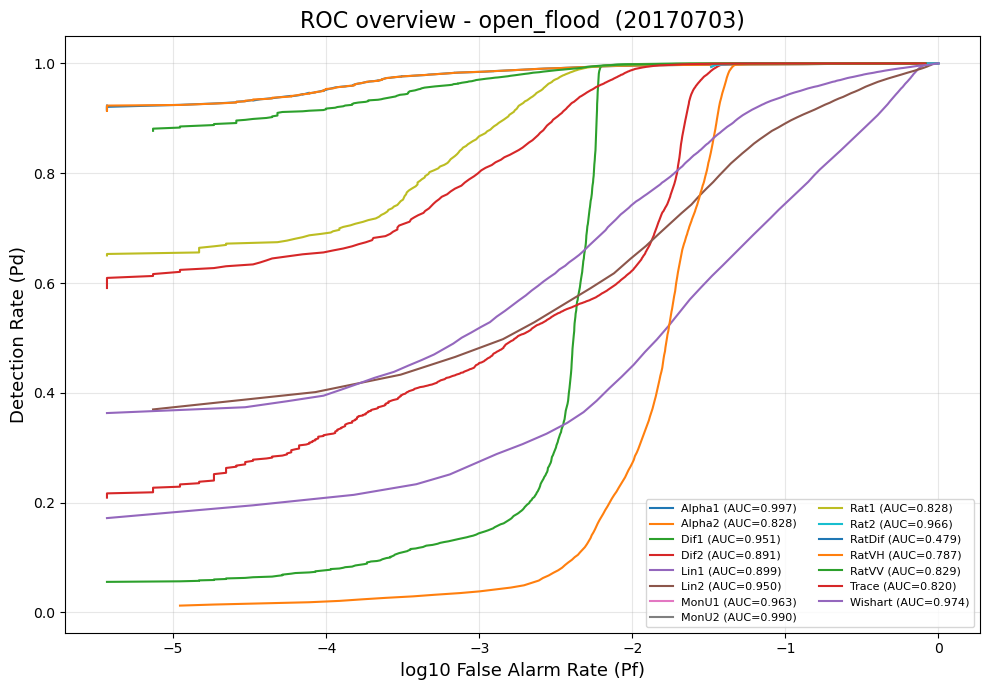

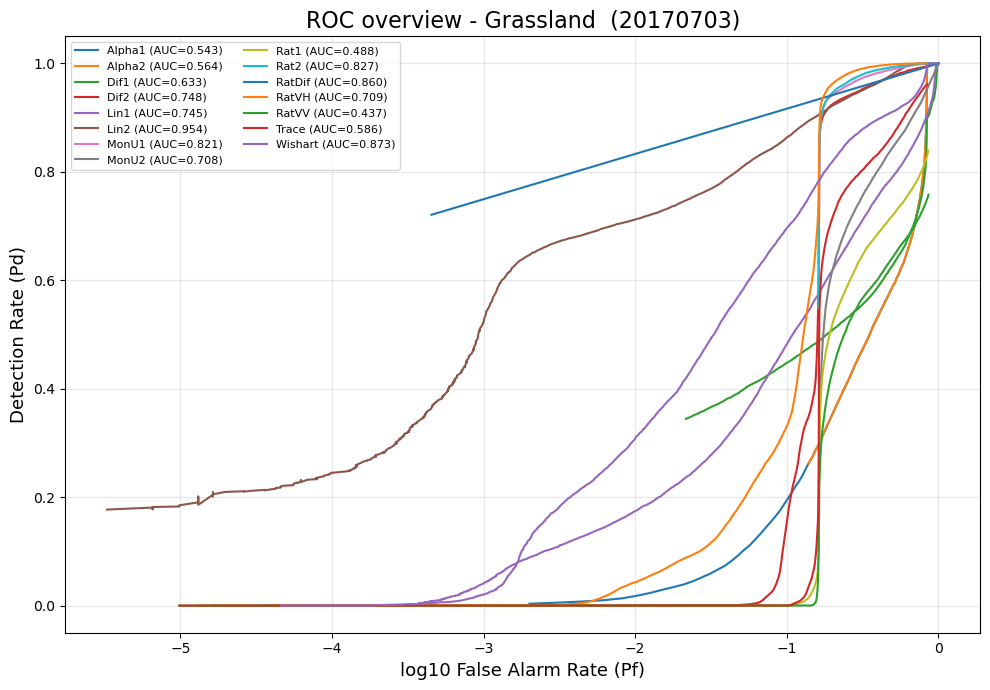

In [29]:
def plot_roc_overview(detectors, masks, cover='Combined', dim=1000,
                      conditions=('Greater', 'Less_than'),
                      open_detected_mask=None, transpose=False,
                      save_path=None, title=None):
    flood, no_flood = cover_masks(masks, cover, open_detected_mask)
    plt.figure(figsize=(10, 7))
    for name, d0 in detectors.items():
        d = np.asarray(d0).T if transpose else np.asarray(d0)
        best_auc, best_df = -np.inf, None
        for condition in conditions:
            df = accuracy_assessment(d, flood, no_flood, dim, condition)
            a = auc_from_df(df)
            if np.isfinite(a) and a > best_auc:
                best_auc, best_df = a, df
        if best_df is None:
            continue
        order = np.argsort(best_df['Pf'].values)
        x = best_df['Pf'].values[order]
        y = best_df['Pd'].values[order]
        with np.errstate(divide='ignore'):
            plt.plot(np.log10(x), y, label=f'{name} (AUC={best_auc:.3f})')
    plt.title(title or f'ROC overview - {cover}', size=16)
    plt.xlabel('log10 False Alarm Rate (Pf)', size=13)
    plt.ylabel('Detection Rate (Pd)', size=13)
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=150)
    return plt.gcf()


for cover in ['Combined', 'open_flood', 'Grassland']:
    plot_roc_overview(det, masks, cover=cover, dim=dim,
                      open_detected_mask=OPEN_DETECTED, transpose=TRANSPOSE,
                      save_path=os.path.join(OUT_DIR, f'roc_{cover}_{DATE}.png'),
                      title=f'ROC overview - {cover}  ({DATE})')
    plt.show()

## 9. Best operating point per detector (threshold selection)

This reproduces the paper's two-stage selection:

1. **AUC screen** — drop any detector whose AUC <= `auc_gate` (default 0.6).
2. **Operating point** — among thresholds that clear the per-cover floors
   (PF / PD / ACC), keep the one with the highest `sort_by` metric (default
   accuracy). Its `THR` is the selected threshold ('best parameter').

Floors default to the values used in the original script (Grassland is looser);
edit `DEFAULT_FLOORS` or pass `floors=` to use the paper's stricter
PD>=0.85 / ACC>=0.85 / PF<=0.20 instead. `auc_method='roc'` uses proper ROC
ordering; pass `auc_method='sortboth'` to match the original script's AUC exactly.

In [30]:
# def _auc_value(df, method='roc'):
#     """'roc' = PD ordered by PF (correct); 'sortboth' = original script's method."""
#     if method == 'sortboth':
#         x = np.sort(df['Pf'].values)
#         y = np.sort(df['Pd'].values)
#         keep = ~(np.isnan(x) | np.isnan(y))
#         return auc(x[keep], y[keep]) if keep.sum() >= 2 else np.nan
#     return auc_from_df(df)


# DEFAULT_FLOORS = {
#     'Grassland':  dict(pf=0.30, pd=0.60, acc=0.60),
#     'open_flood': dict(pf=0.15, pd=0.70, acc=0.70),
#     'Combined':   dict(pf=0.15, pd=0.70, acc=0.70),
# }


# def best_operating_points(detectors, masks, dim=1000,
#                           conditions=('Greater', 'Less_than'),
#                           covers=('Grassland', 'open_flood', 'Combined'),
#                           open_detected_mask=None, transpose=False,
#                           auc_gate=0.6, auc_method='roc',
#                           floors=None, sort_by='accuracy'):
#     """Screen by AUC, then pick the best-accuracy threshold per detector/cover/condition."""
#     floors = floors or DEFAULT_FLOORS
#     combos = [(n, c, cond) for n in detectors for c in covers for cond in conditions]
#     rows = []
#     for name, cover, condition in tqdm(combos, desc='best-params'):
#         d = np.asarray(detectors[name]).T if transpose else np.asarray(detectors[name])
#         flood, no_flood = cover_masks(masks, cover, open_detected_mask)
#         df = accuracy_assessment(d, flood, no_flood, dim, condition)
#         a = _auc_value(df, auc_method)
#         if not np.isfinite(a) or a <= auc_gate:
#             continue
#         fl = floors[cover]
#         sel = df[(df['Pf'] < fl['pf']) & (df['Pd'] > fl['pd']) & (df['accuracy'] > fl['acc'])]
#         if sel.empty:                       # no threshold clears the floors -> skip
#             continue
#         best = sel.sort_values(sort_by, ascending=False).iloc[0]
#         rows.append({'Detector': name, 'cover': cover, 'condition': condition,
#                      'AUC': round(float(a), 4), 'THR': float(best['threshold']),
#                      'PD': float(best['Pd']), 'PF': float(best['Pf']),
#                      'ACC': float(best['accuracy']), 'F1': float(best['fscore']),
#                      'PREC': float(best['precision'])})
#     return pd.DataFrame(rows, columns=['Detector', 'cover', 'condition', 'AUC',
#                                        'THR', 'PD', 'PF', 'ACC', 'F1', 'PREC'])


# best_ops = best_operating_points(det, masks, dim=dim,
#                                  open_detected_mask=OPEN_DETECTED, transpose=TRANSPOSE,
#                                  auc_gate=0.6, auc_method='roc')

# best_ops.to_csv(os.path.join(OUT_DIR, f'best_operating_points_{DATE}.csv'), index=False)
# print(f'{len(best_ops)} detector/cover/condition combinations passed the screen')
# best_ops

In [31]:
def direction_matrix(best_ops, rank_by='ACC'):
    """Per detector: the chosen direction for each cover + whether open≠grassland."""
    best = (best_ops.sort_values(rank_by, ascending=False)
                    .groupby(['Detector', 'cover'], as_index=False).head(1))
    piv = best.pivot_table(index='Detector', columns='cover',
                           values='condition', aggfunc='first')
    o = piv['open_flood'] if 'open_flood' in piv else pd.Series(index=piv.index, dtype=object)
    g = piv['Grassland']  if 'Grassland'  in piv else pd.Series(index=piv.index, dtype=object)
    piv['separable'] = o.notna() & g.notna() & (o != g)
    return piv


def separable_detectors(best_ops, rank_by='ACC'):
    """
    Keep:
      - every 'Combined' row (best per detector),
      - for open/grassland: if the two are detected in DIFFERENT directions
        (separable) -> keep BOTH; otherwise (same direction, confused) ->
        keep ONLY 'open_flood'.
    A 'separable' column flags which open/grassland rows are true separations.
    """
    best = (best_ops.sort_values(rank_by, ascending=False)
                    .groupby(['Detector', 'cover'], as_index=False).head(1))

    rows = [best[best['cover'] == 'Combined'].assign(separable=pd.NA)]

    og = best[best['cover'].isin(['open_flood', 'Grassland'])]
    for name, grp in og.groupby('Detector'):
        dirs = dict(zip(grp['cover'], grp['condition']))
        sep = ('open_flood' in dirs and 'Grassland' in dirs
               and dirs['open_flood'] != dirs['Grassland'])
        if sep:
            rows.append(grp.assign(separable=True))                        # open + grassland
        else:
            rows.append(grp[grp['cover'] == 'open_flood'].assign(separable=False))  # open only
    out = pd.concat(rows, ignore_index=True)
    return out.sort_values(['cover', 'Detector']).reset_index(drop=True)

print(direction_matrix(best_ops))          # diagnostic: who separates the classes

sep = separable_detectors(best_ops)
sep.to_csv(os.path.join(OUT_DIR, f'separable_detectors_{DATE}.csv'), index=False)
sep

cover      Combined  Grassland open_flood  separable
Detector                                            
Alpha1      Greater        NaN    Greater      False
Alpha2    Less_than        NaN  Less_than      False
Dif1      Less_than        NaN  Less_than      False
Dif2      Less_than  Less_than  Less_than      False
Lin1            NaN    Greater  Less_than       True
Lin2            NaN    Greater  Less_than       True
MonU1       Greater    Greater    Greater      False
MonU2       Greater    Greater    Greater      False
Rat1      Less_than        NaN  Less_than      False
Rat2        Greater    Greater    Greater      False
RatDif          NaN    Greater        NaN      False
RatVH     Less_than  Less_than  Less_than      False
RatVV     Less_than        NaN  Less_than      False
Trace     Less_than        NaN  Less_than      False
Wishart   Less_than    Greater  Less_than       True


,Detector,cover,condition,AUC,THR,PD,PF,ACC,F1,PREC,separable
0,Alpha1,Combined,Greater,0.8741,0.427823,0.783403,0.011419,0.885992,0.872959,0.985633,<NA>
1,Alpha2,Combined,Less_than,0.7161,1.140938,0.783220,0.011254,0.885983,0.872924,0.985835,<NA>
2,Dif1,Combined,Less_than,0.8309,0.012708,0.793947,0.004502,0.894722,0.882924,0.994361,<NA>
3,Dif2,Combined,Less_than,0.8866,0.002650,0.971516,0.005162,0.983177,0.982979,0.994715,<NA>
4,MonU1,Combined,Greater,0.9915,-0.136714,0.976446,0.007815,0.984315,0.984191,0.992060,<NA>
5,MonU2,Combined,Greater,0.9595,-0.224784,0.889700,0.021688,0.934006,0.930947,0.976204,<NA>
6,Rat1,Combined,Less_than,0.7671,1.627528,0.863636,0.015360,0.924138,0.919252,0.982526,<NA>
7,Rat2,Combined,Greater,0.9962,0.843169,0.975533,0.006936,0.984298,0.984160,0.992940,<NA>
8,RatVH,Combined,Less_than,0.7920,1.307984,0.980159,0.005605,0.987277,0.987185,0.994314,<NA>
9,RatVV,Combined,Less_than,0.7569,1.406341,0.842151,0.017931,0.912110,0.905499,0.979152,<NA>
